# 412 – Variational Quantum Classifier (`VQC`)

`VQC` packages everything from `411` into one object: give it a **feature map**, an
**ansatz** and an **optimiser**, and it builds the `SamplerQNN`, the interpretation of the
measurement and the classifier for you.  It expects **one-hot** labels and trains with the
**cross-entropy** loss.


| Notebook | Model | Network output | Labels |
|---|---|---|---|
| `410` | `EstimatorQNN` + `NeuralNetworkClassifier` | expectation value $\langle Z\otimes Z\rangle \in [-1, 1]$ | $-1$ / $+1$ |
| `411` | `SamplerQNN` + `NeuralNetworkClassifier` | probabilities of the 2 classes (via parity of the bitstring) | $0$ / $1$ |
| `412` | `VQC` (all-in-one) | class probabilities | one-hot |

**You will learn to** train a `VQC` and recognise that it is the same model as the
`SamplerQNN` classifier of `411`.

**Prerequisites:** `411`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.algorithms.classifiers import VQC

algorithm_globals.random_seed = 42

In [3]:
# primitives replace the old QuantumInstance
estimator = StatevectorEstimator()
sampler = StatevectorSampler(default_shots=1024)

## The dataset

20 random points in the square $[-1, 1]^2$.  A point belongs to class **+1** (blue) if
$x_0 + x_1 \ge 0$ and to class **−1** (green) otherwise – the two classes are separated by the
dashed diagonal.  The same data (same seed) is used in `410`, `411` and `412`, so you can compare
the three models directly.  Three label formats are prepared: `y` ($\pm 1$), `y01` ($0/1$) and
`y_one_hot`.

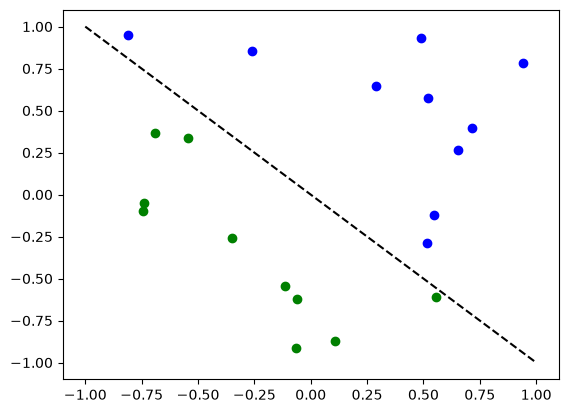

In [4]:
num_inputs = 2
num_samples = 20
X = 2 * algorithm_globals.random.random([num_samples, num_inputs]) - 1
y01 = 1 * (np.sum(X, axis=1) >= 0)  # in { 0,  1}
y = 2 * y01 - 1  # in {-1, +1}
y_one_hot = np.zeros((num_samples, 2))
for i in range(num_samples):
    y_one_hot[i, y01[i]] = 1

for x, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Feature map and ansatz

The same two circuits as in `411`.  This time we do **not** compose them ourselves – `VQC`
does it.

In [5]:
# construct feature map
feature_map = zz_feature_map(num_inputs)

# construct ansatz
ansatz = real_amplitudes(num_inputs, reps=1)

## Training

`qiskit-machine-learning` classifiers follow the **scikit-learn** interface: `fit`, `predict`,
`score`.  Training is a classical optimisation of the circuit weights; here we use **COBYLA**,
a gradient-free optimiser that works well for a handful of parameters.

The callback below redraws the objective (loss) after every optimiser step, so you can watch the
training happen.

In [6]:
# callback function that draws a live plot when the .fit() method is called
def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [7]:
# construct variational quantum classifier
vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    loss="cross_entropy",
    optimizer=COBYLA(),
    sampler=sampler,
    callback=callback_graph,
)

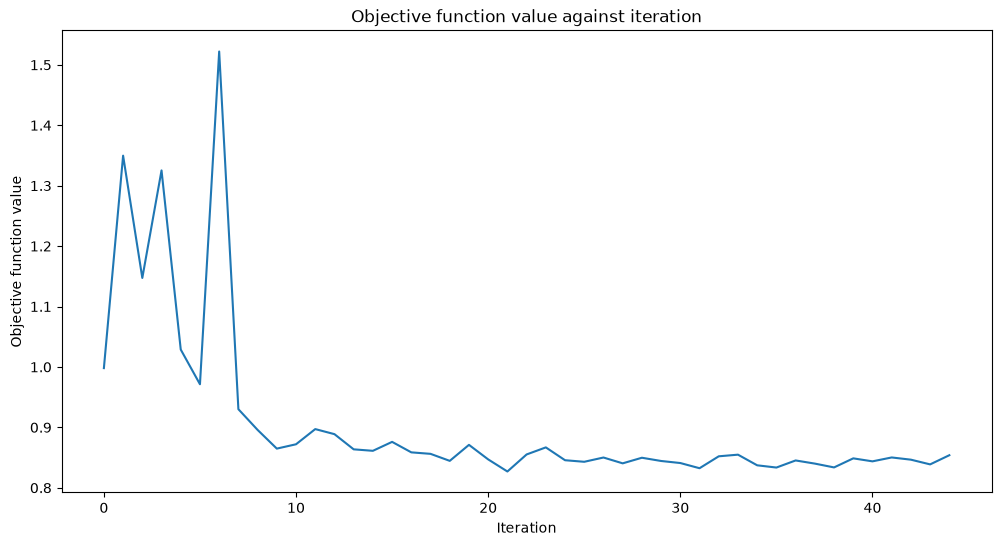

accuracy on the training data: 0.65


In [8]:
# create empty array for callback to store evaluations of the objective function
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

# fit classifier to data
vqc.fit(X, y_one_hot)

# return to default figsize
plt.rcParams["figure.figsize"] = (6, 4)

# score classifier
print("accuracy on the training data:", vqc.score(X, y_one_hot))

## Evaluating the result

Blue / green dots are the two classes; a **red circle** marks a point the trained model gets
wrong.  `score` is the accuracy on the given data.

Don't expect 100 % here.  The ZZ feature map bends the data in a complicated way that does not
suit a straight-line boundary, and COBYLA stops after a fixed budget of steps.  Accuracies of
roughly 65–85 % are typical for this example (exercises 1–2 explore why).

> We score on the *training* data to keep the example short.  A fair evaluation needs separate
> test data – see `413` and `415`, and exercise 3 below.

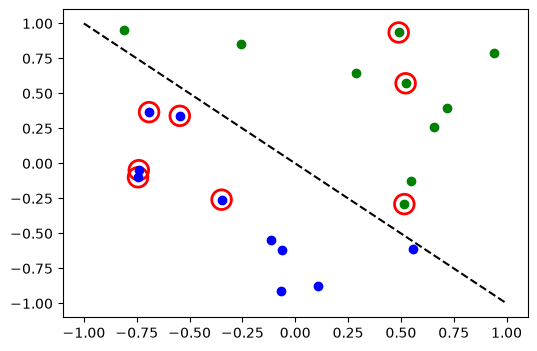

In [9]:
# evaluate data points
y_predict = vqc.predict(X)

# plot results
# red == wrongly classified
for x, y_target, y_p in zip(X, y_one_hot, y_predict):
    if y_target[0] == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
    if not np.all(y_target == y_p):
        plt.scatter(x[0], x[1], s=200, facecolors="none", edgecolors="r", linewidths=2)
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Key takeaways
* `VQC` = feature map + ansatz + `SamplerQNN` + one-hot cross-entropy training, in one class.
* The three notebooks `410`–`412` show that the *model* is always the same idea – encoding,
  trainable circuit, measurement – only the packaging differs.

## Try it yourself
1. Print `vqc.circuit` and compare it with the circuit you built in `411`.
2. Change `loss="cross_entropy"` to `loss="squared_error"`.  Any difference?
3. VQC also handles more than two classes: create labels with three classes (e.g. by the angle
   of each point) and one-hot encode them with three columns.

**Next:** `413-VQC-AdHoc-Dataset` – VQC on a dataset designed to be hard for classical models,
with a proper train / test split.